# 4.4. Softmax Regression Implementation from Scratch

In [1]:
import torch
from d2l import torch as d2l

## 4.4.1. The Softmax

In [2]:
X = torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
X.sum(axis=0, keepdims=True), X.sum(axis=1, keepdims=True)

(tensor([[5., 7., 9.]]),
 tensor([[ 6.],
         [15.]]))

In [3]:
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(axis=1, keepdims=True)
    return X_exp / partition  # The broadcasting mechanism is applied here

In [4]:
X = torch.rand((2, 5))
X_prob = softmax(X)
X_prob, X_prob.sum(1)

(tensor([[0.1300, 0.2666, 0.2124, 0.1445, 0.2465],
         [0.2921, 0.2027, 0.1512, 0.1780, 0.1759]]),
 tensor([1., 1.]))

## 4.4.2. The Model

In [5]:
class SoftmaxRegressionScratch(d2l.Classifier):
    def __init__(self, num_inputs, num_outputs, lr, sigma=0.01):
        super().__init__()
        self.save_hyperparameters()
        self.W = torch.normal(0, sigma, size=(num_inputs, num_outputs), requires_grad=True)
        self.b = torch.zeros(num_outputs, requires_grad=True)

    def parameters(self):
        return [self.W, self.b]

In [6]:
@d2l.add_to_class(SoftmaxRegressionScratch)
def forward(self, X):
    X = X.reshape((-1, self.W.shape[0]))
    return softmax(torch.matmul(X, self.W) + self.b)

## 4.4.3. The Cross-Entropy Loss

In [7]:
y = torch.tensor([0, 2])
y_hat = torch.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]])
y_hat[[0, 1], y]

tensor([0.1000, 0.5000])

In [8]:
def cross_entropy(y_hat, y):
    return -torch.log(y_hat[list(range(len(y_hat))), y]).mean()

cross_entropy(y_hat, y)

tensor(1.4979)

In [9]:
@d2l.add_to_class(SoftmaxRegressionScratch)
def loss(self, y_hat, y):
    return cross_entropy(y_hat, y)

## 4.4.4. Training

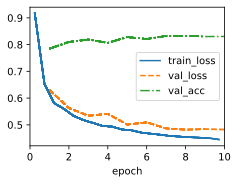

In [10]:
data = d2l.FashionMNIST(batch_size=256)
model = SoftmaxRegressionScratch(num_inputs=784, num_outputs=10, lr=0.1)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

## 4.4.5. Prediction

In [11]:
X, y = next(iter(data.val_dataloader()))
preds = model(X).argmax(axis=1)
preds.shape

torch.Size([256])

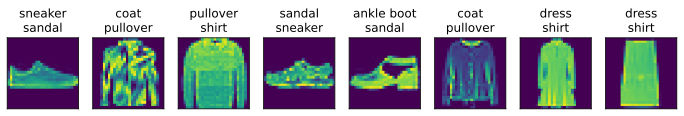

In [12]:
wrong = preds.type(y.dtype) != y
X, y, preds = X[wrong], y[wrong], preds[wrong]
labels = [a + '\n' + b for a, b in zip(data.text_labels(y), data.text_labels(preds))]
data.visualize([X, y], labels=labels)

## 4.4.7. Exercises

In [13]:
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(axis=1, keepdims=True)
    return X_exp / partition  # The broadcasting mechanism is applied here

X = torch.rand((2, 5))
X[:,0] = -100
X_exp = torch.exp(X)
X_prob = softmax(X)
X, X_exp, X_prob, X_prob.sum(1)

(tensor([[-1.0000e+02,  9.5571e-01,  3.9488e-01,  3.9247e-01,  8.3271e-01],
         [-1.0000e+02,  2.7728e-01,  1.2948e-01,  3.7871e-01,  4.5319e-02]]),
 tensor([[3.7835e-44, 2.6005e+00, 1.4842e+00, 1.4806e+00, 2.2995e+00],
         [3.7835e-44, 1.3195e+00, 1.1382e+00, 1.4604e+00, 1.0464e+00]]),
 tensor([[4.2039e-45, 3.3065e-01, 1.8871e-01, 1.8826e-01, 2.9238e-01],
         [7.0065e-45, 2.6579e-01, 2.2927e-01, 2.9417e-01, 2.1077e-01]]),
 tensor([1., 1.]))

In [14]:
def new_softmax(X):
    X_max, _ = torch.max(X, dim=1, keepdims=True)
    X_exp = torch.exp(X - X_max)
    partition = X_exp.sum(axis=1, keepdims=True)
    return X_exp / partition  # The broadcasting mechanism is applied here

X_prob = new_softmax(X)
X_prob, X_prob.sum(1)

(tensor([[4.2039e-45, 3.3065e-01, 1.8871e-01, 1.8826e-01, 2.9238e-01],
         [7.0065e-45, 2.6579e-01, 2.2927e-01, 2.9417e-01, 2.1077e-01]]),
 tensor([1., 1.]))